# 01 · Data Exploration

Goals of this notebook:
1. Show the **malformed header** in the Fronkon `games.csv` and why every load goes through `src/data/loaders.py`.
2. Justify the **preparation rules** (description length, tag presence, Latin-script filter, BBCode cleanup).
3. Fix the **label space**: the 22 tags with at least 10,000 games each.
4. Explore the **reviews** (41M rows) used by the Reception Estimator, including class balance and time span.

In [1]:
# Pin the SageMaker SDK v2 API used by this project (no-op if already installed)
%pip install -q "sagemaker>=2.232,<3"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import warnings

warnings.filterwarnings("ignore")
def find_repo_root():
    """The notebooks import from src/, so the whole repo must be cloned, not just notebooks/."""
    candidates = [os.path.expanduser("~/steam-store-copilot")]
    try:  # the kernel's working directory may have been deleted (e.g. after re-cloning)
        candidates = [os.getcwd(), os.path.dirname(os.getcwd())] + candidates
    except FileNotFoundError:
        os.chdir(os.path.expanduser("~"))
    for path in candidates:
        if os.path.isdir(os.path.join(path, "src")) and os.path.exists(os.path.join(path, "src", "config.py")):
            return path
    raise RuntimeError("Could not find the repo's src/ folder. Clone the full repository in Studio "
                       "(Git > Clone Repository) and open the notebooks from steam-store-copilot/notebooks/.")


REPO_ROOT = find_repo_root()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
print("Repo root:", REPO_ROOT)

import logging

for _name in ("sagemaker", "sagemaker.config", "botocore.credentials"):
    logging.getLogger(_name).setLevel(logging.ERROR)  # keep SDK log noise out of the outputs

import boto3
import sagemaker

from src.config import S3Layout

# Works both inside SageMaker Studio and on a laptop with Learner Lab credentials in ~/.aws/credentials
boto_session = boto3.Session(region_name=boto3.Session().region_name or "us-east-1")
sess = sagemaker.Session(boto_session=boto_session)
region = sess.boto_region_name
if os.path.exists("/opt/ml/metadata/resource-metadata.json"):  # inside SageMaker Studio
    role = sagemaker.get_execution_role(sagemaker_session=sess)
else:  # laptop with Learner Lab credentials: jobs run as the lab's execution role
    account = boto_session.client("sts").get_caller_identity()["Account"]
    role = f"arn:aws:iam::{account}:role/LabRole"
layout = S3Layout(bucket=sess.default_bucket())
sm = boto3.client("sagemaker", region_name=region)
print("Region:", region)
print("Role:  ", role)
print("Bucket:", layout.bucket)

Repo root: /Users/yatharthvardan/Documents/USD/steam-store-copilot


Region: us-east-1
Role:   arn:aws:iam::326278567375:role/LabRole
Bucket: sagemaker-us-east-1-326278567375


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import preprocess as pp
from src.data.loaders import STORE_COLUMNS, iter_recommendations, load_recs_games, load_store_games, load_users
from src.data.s3io import fetch, stream

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
store_path = fetch(f"{layout.raw}/store/games.csv")

## 1. The malformed header
The header has 39 names but every row has 40 values (a comma is missing between `Discount` and `DLC count`).
A naive `pd.read_csv` silently shifts every column from index 7 onward.

In [4]:
with open(store_path, encoding="utf-8") as fh:
    header = fh.readline().rstrip("\n").split(",")
print("Header fields:", len(header), "| pinned schema fields:", len(STORE_COLUMNS))
print([h for h in header if "Discount" in h])

naive = pd.read_csv(store_path, nrows=20000, index_col=False)
print("\nNaive read - most common values in 'Tags' (actually another column):")
print(naive["Tags"].astype(str).str.split(",").explode().value_counts().head(8))
del naive  # free memory before loading the full file

Header fields: 39 | pinned schema fields: 40
['DiscountDLC count']



Naive read - most common values in 'Tags' (actually another column):
Tags
Indie           13231
Casual           8285
Action           7561
Adventure        7321
Simulation       3944
Strategy         3605
RPG              3361
Free To Play     1993
Name: count, dtype: int64


In [5]:
games = load_store_games(store_path)
print(f"{len(games):,} games loaded with the pinned 40-column schema")
games[["app_id", "name", "price", "required_age", "windows", "tags"]].head()

125,855 games loaded with the pinned 40-column schema


,app_id,name,price,required_age,windows,tags
0,2539430,Black Dragon Mage Playtest,0.00,0,True,[]
1,496350,Supipara - Chapter 1 Spring Has Come!,5.24,0,True,"[Adventure, Visual Novel, Anime, Cute]"
2,1034400,Mystery Solitaire The Black Raven,4.99,0,True,"[Casual, Card Game, Solitaire, Puzzle, Hidden ..."
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,8.99,0,True,[]
4,3631080,Maze Quest VR,4.99,0,True,[]


## 2. Preparation funnel

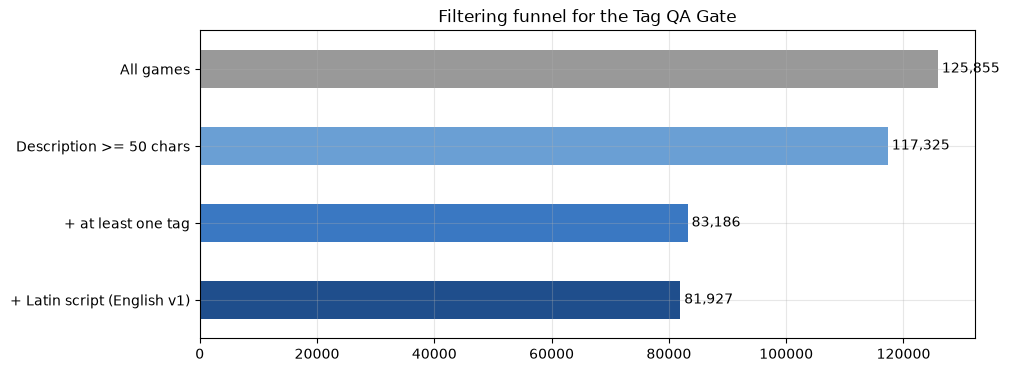

BBCode present in 0.55% of raw descriptions


In [6]:
# Build the cleaned dataset once with the production code, then count each funnel stage.
tag_ds = pp.build_tag_dataset(games)
clean_len = games["description"].map(lambda s: len(pp.strip_bbcode(s)))
long_desc = clean_len >= pp.MIN_DESCRIPTION_CHARS
has_tags = games["tags"].map(len) > 0
funnel = pd.Series({
    "All games": len(games),
    "Description >= 50 chars": int(long_desc.sum()),
    "+ at least one tag": int((long_desc & has_tags).sum()),
    "+ Latin script (English v1)": len(tag_ds),
})
ax = funnel.plot.barh(color=["#999", "#6a9fd4", "#3a78c2", "#1f4e8c"])
ax.invert_yaxis()
for i, v in enumerate(funnel):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_title("Filtering funnel for the Tag QA Gate")
plt.show()
bbcode_share = games["description"].str.contains(r"\[/?[a-z]+", regex=True).mean()
print(f"BBCode present in {bbcode_share:.2%} of raw descriptions")
del clean_len, long_desc, has_tags

452 distinct tags across 81,927 kept games


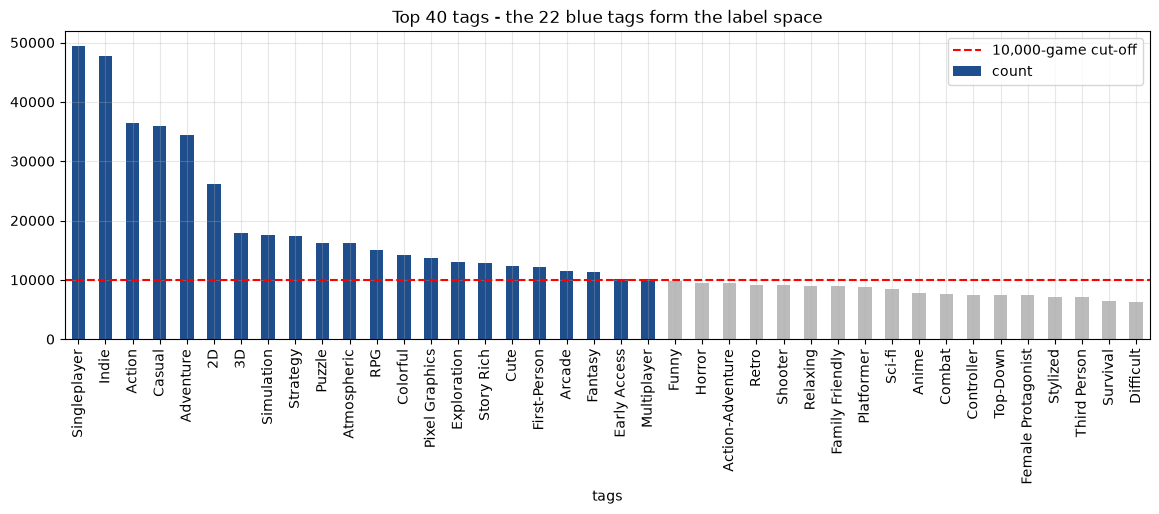

In [7]:
kept_tags = games.loc[games["app_id"].isin(tag_ds["app_id"]), "tags"]
tag_counts = kept_tags.explode().value_counts()
print(f"{tag_counts.size} distinct tags across {len(tag_ds):,} kept games")

top = tag_counts.head(40)
colors = ["#1f4e8c" if c >= pp.MIN_GAMES_PER_TAG else "#bbb" for c in top]
ax = top.plot.bar(color=colors, figsize=(14, 4))
ax.axhline(pp.MIN_GAMES_PER_TAG, color="red", ls="--", label="10,000-game cut-off")
ax.set_title("Top 40 tags - the 22 blue tags form the label space")
ax.legend()
plt.show()
assert set(tag_counts[tag_counts >= pp.MIN_GAMES_PER_TAG].index) == set(pp.TAGS)

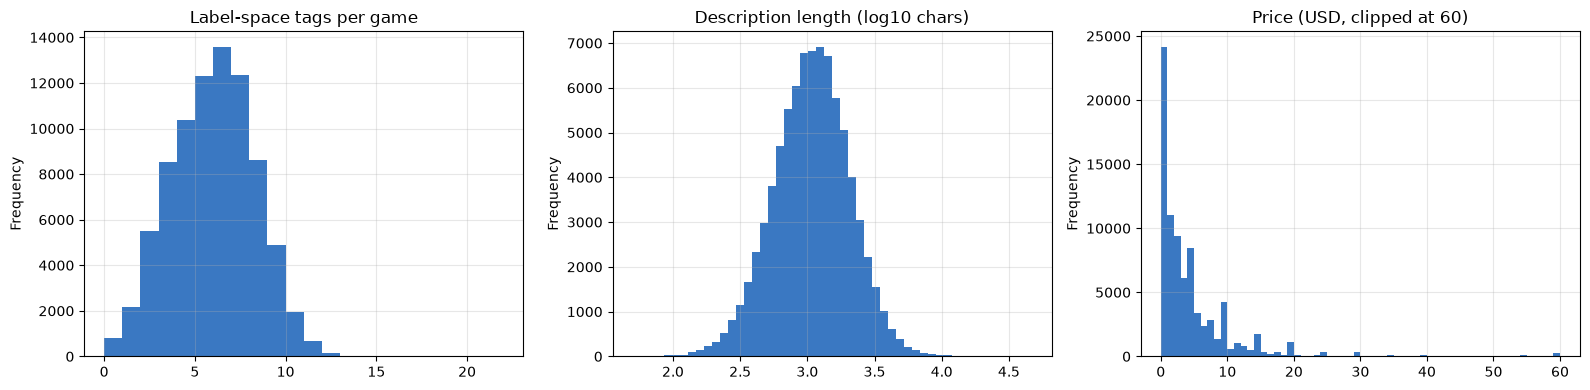

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
tag_ds["n_tags_22"].plot.hist(bins=range(0, 23), ax=axes[0], color="#3a78c2")
axes[0].set_title("Label-space tags per game")
np.log10(tag_ds["desc_chars"]).plot.hist(bins=50, ax=axes[1], color="#3a78c2")
axes[1].set_title("Description length (log10 chars)")
tag_ds["price"].clip(upper=60).plot.hist(bins=60, ax=axes[2], color="#3a78c2")
axes[2].set_title("Price (USD, clipped at 60)")
plt.tight_layout()
plt.show()

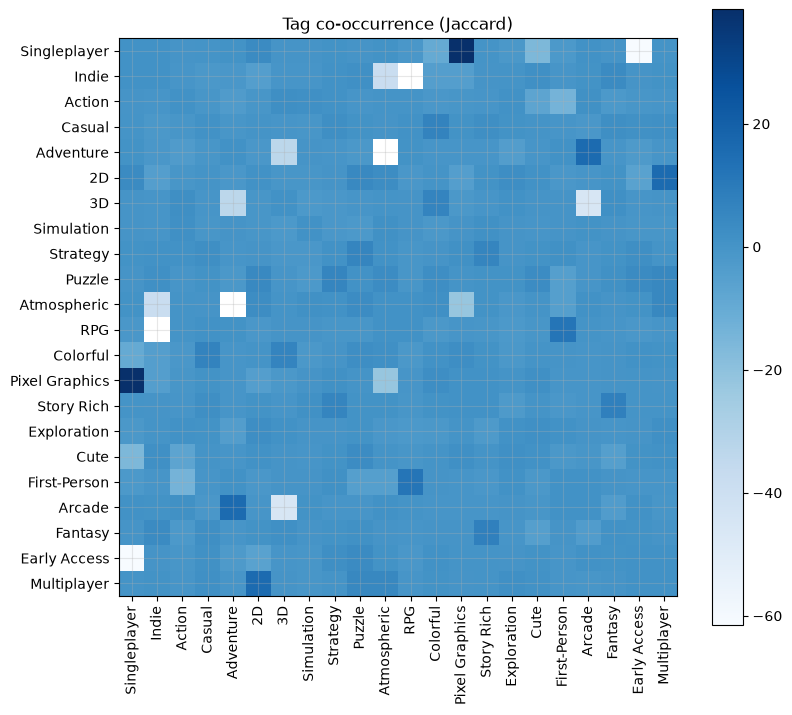

In [9]:
Y = pp.labels_matrix(tag_ds["tags_22"])
co = Y.T @ Y
jaccard = co / (np.add.outer(np.diag(co), np.diag(co)) - co)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(jaccard, cmap="Blues")
ax.set_xticks(range(22), pp.TAGS, rotation=90)
ax.set_yticks(range(22), pp.TAGS)
ax.set_title("Tag co-occurrence (Jaccard)")
fig.colorbar(im)
plt.show()

## 3. Splits
Games released on/after **2025-01-01** are held out as the *incoming drafts* stream (batch inference and drift
monitoring). Older games are split 80/10/10 by a hash of `app_id`, which is deterministic and reproducible.

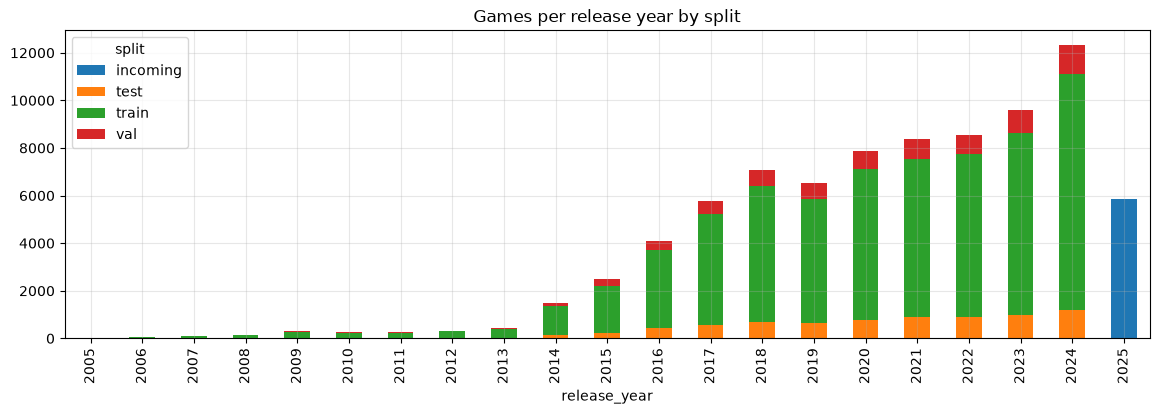

split
train       60934
test         7677
val          7461
incoming     5855
Name: count, dtype: int64

In [10]:
yearly = tag_ds.groupby(["release_year", "split"]).size().unstack(fill_value=0)
yearly.loc[2005:].plot.bar(stacked=True, figsize=(14, 4), title="Games per release year by split")
plt.show()
tag_ds["split"].value_counts()

## 4. Reviews (Reception Estimator)
41M reviews are streamed from S3 in chunks; we count classes on the full file and keep a 5% sample for plots.

In [11]:
totals, parts = {"rows": 0, "negative": 0}, []
for chunk in iter_recommendations(stream(f"{layout.raw}/recs/recommendations.csv"), chunksize=4_000_000):
    totals["rows"] += len(chunk)
    totals["negative"] += int((~chunk["is_recommended"]).sum())
    parts.append(chunk.sample(frac=0.05, random_state=0))
reviews = pd.concat(parts, ignore_index=True)
print(f"{totals['rows']:,} reviews | negative (minority) = {totals['negative']:,} "
      f"({totals['negative'] / totals['rows']:.2%})")

41,154,794 reviews | negative (minority) = 5,850,396 (14.22%)


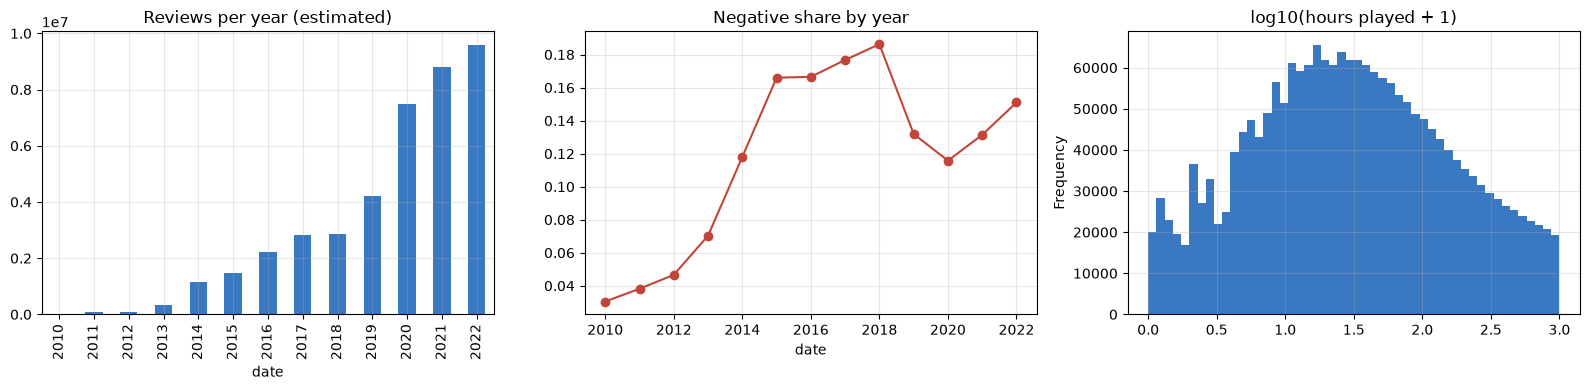

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
by_year = reviews.groupby(reviews["date"].dt.year)["is_recommended"].agg(["size", "mean"])
by_year["size"].mul(20).plot.bar(ax=axes[0], color="#3a78c2", title="Reviews per year (estimated)")
(1 - by_year["mean"]).plot(ax=axes[1], marker="o", color="#c2453a", title="Negative share by year")
np.log10(reviews["hours"] + 1).plot.hist(bins=50, ax=axes[2], color="#3a78c2", title="log10(hours played + 1)")
plt.tight_layout()
plt.show()

In [13]:
users = load_users(fetch(f"{layout.raw}/recs/users.csv"))
recs_games = load_recs_games(fetch(f"{layout.raw}/recs/games.csv"))
print(f"users: {len(users):,} | recs games: {len(recs_games):,}")
coverage = recs_games["app_id"].isin(games["app_id"]).mean()
print(f"Join coverage recs games -> store games on app_id: {coverage:.1%}")
print(f"Reviews whose game has draft features: {reviews['app_id'].isin(tag_ds['app_id']).mean():.1%}")

users: 14,306,064 | recs games: 50,872
Join coverage recs games -> store games on app_id: 77.5%
Reviews whose game has draft features: 94.7%


## Findings
* The pinned loader is mandatory: the naive read produces wrong tags.
* After filtering, ~82k English games remain; 22 tags have >= 10k games each, which meets the 10k-labels-per-class guideline.
* Reviews are 85.8% positive / 14.2% negative, with millions of minority examples, and the most recent period is held out
  chronologically for the reception model.
* Post-release signals (reviews, playtime, CCU, owners) must never reach the tag model; this is enforced in the Feature
  Store design (notebook 02).